# Slicer de pulsos
El objetivo de este script es pasarle una señal EMG y tener como resultado una colección de marcadores de tiempo donde se situen todos los pulsos presentes en el archivo.

## Cargar los datos y leerlos
Aseguramos que el entorno sea capaz de leer y acceder correctamente a la base de datos.

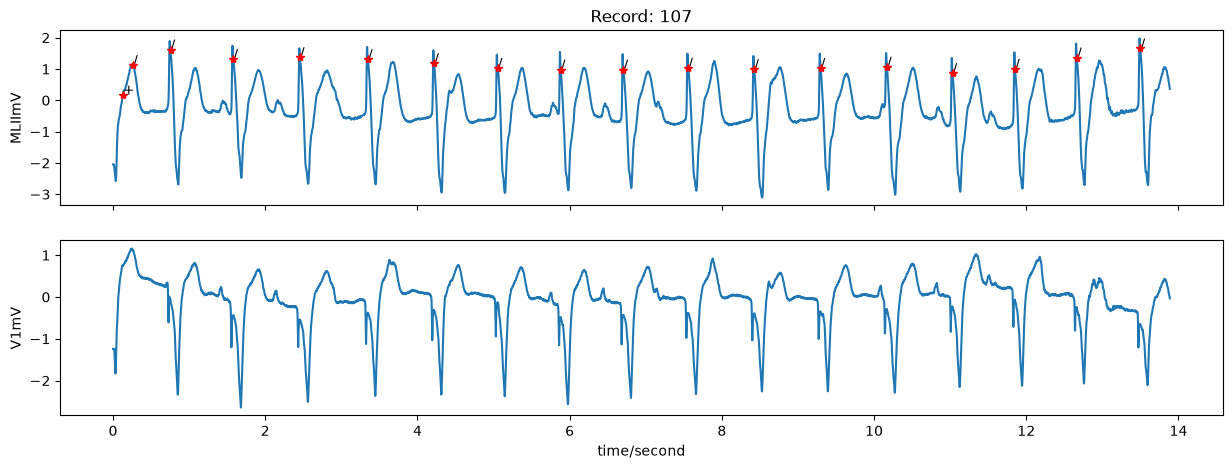

In [1]:
import wfdb

# Definir el rango en muestras (ej. primeros 3 segundos a 360 Hz)
inicio = 0

ruta=r'Data\Database\107'
fin = 5000

# 1. Leer solo el rango especificado
record = wfdb.rdrecord(ruta, sampfrom=inicio, sampto=fin)
annotation = wfdb.rdann(ruta, 'atr', sampfrom=inicio, sampto=fin)

# 2. Graficar modificando el tamaño (ej. 15 de ancho por 5 de alto)
wfdb.plot_wfdb(
    record=record, 
    annotation=annotation, 
    plot_sym=True, 
    figsize=(15, 5) # <- Modifica el largo y alto aquí
)

Solo se busca trabajar con el primer canal, entonces lo extraemos y trabajaremos sobre él.

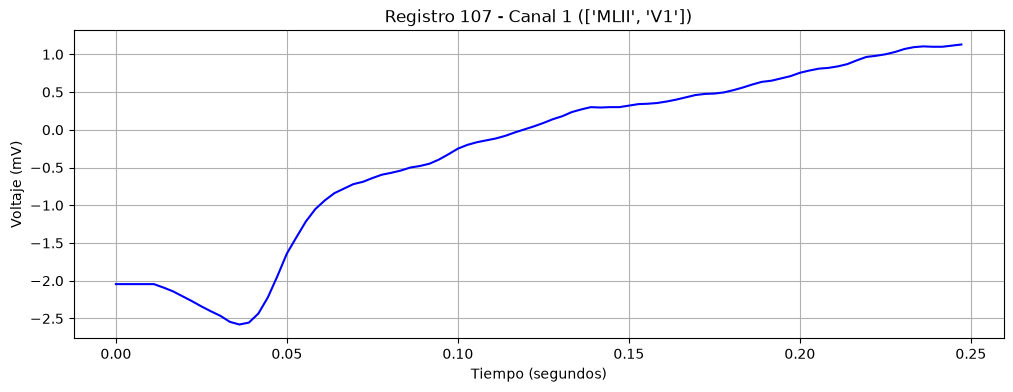

In [2]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Cargar el registro (.dat + .hea)
record = wfdb.rdrecord(ruta)  # Reemplaza '100' por la ruta de tu registro

# 2. Extraer únicamente el Canal 0 (la primera gráfica)
voltaje_ch0 = record.p_signal[:, 0]  # Voltaje en mV

# 3. Construir el vector de tiempo en segundos (frecuencia fs = 360 Hz)
tiempo = np.arange(len(voltaje_ch0)) / record.fs

# 4. Graficar un ventana (por ejemplo, los primeros 10 segundos)
muestras_10s = int(record.fs * 0.25)  # 360 muestras/seg * 10 seg = 3600 muestras

plt.figure(figsize=(12, 4))
plt.plot(tiempo[:muestras_10s], voltaje_ch0[:muestras_10s], color='blue')
plt.title(f'Registro {record.record_name} - Canal 1 ({record.sig_name})')
plt.xlabel('Tiempo (segundos)')
plt.ylabel('Voltaje (mV)')
plt.grid(True)
plt.show()

# Registro de los picos

Analizaré las distancias máximas que se presentan y las mínimas en cada paso

In [3]:
distancias=[]
for i in range (len(voltaje_ch0)-1):
    distancias.append(voltaje_ch0[i+1]-voltaje_ch0[i])


In [4]:
print(max(distancias))
print(min(distancias))

0.6350000000000002
-0.4650000000000001



Se tomará como criterio una pendiente de $50 \frac{v}{s}$ para decidir donde se encuentra la punta del pulso.
La frecuencia de sampleo es de $360 HZ$ por lo tanto $\frac{50 v}{360 m}=0.13 \frac{v}{m}$

1. Recorremos los datos
2. Si encontramos una pendiente igual o mayor a esta iniciamos un periodo de atención
3. Medimos la diferencia con el anterior
4. Nos mantenemos registrando la pendiente hasta que esta sea igual o menor a 0 (comience a caer)
5. Registramos el punto de inflexión

In [5]:
PENDIENTE = 0.13
pulsos = []
i = 0  # Inicializamos el índice manualmente

# Recorremos hasta el penúltimo dato
while i < len(voltaje_ch0) - 1:
    valorSiguiente = voltaje_ch0[i+1]
    valorActual = voltaje_ch0[i]

    # Si detectamos la pendiente (inicio del pico)
    if (valorSiguiente - valorActual) >= PENDIENTE:
        
        # Avanzamos MIENTRAS siga subiendo y no nos salgamos del arreglo
        while i < len(voltaje_ch0) - 1 and voltaje_ch0[i+1] >= voltaje_ch0[i]:
            i += 1
            
        # Cuando el while termina, 'i' está en la cima del pico
        pulsos.append(i)
        
    else:
        # Si no hay pendiente suficiente, simplemente avanzamos un paso
        i += 1

print(pulsos)

[50, 268, 381, 565, 685, 881, 973, 1202, 1323, 1515, 1591, 1816, 1933, 2114, 2225, 2411, 2496, 2717, 2845, 3029, 3113, 3343, 3432, 3657, 3784, 3968, 4057, 4264, 4379, 4556, 4611, 4856, 4913, 5166, 5227, 5487, 5614, 5801, 5923, 6106, 6226, 6404, 6461, 6708, 6762, 7010, 7067, 7315, 7439, 7630, 7751, 7942, 8002, 8251, 8332, 8547, 8664, 8841, 8957, 9139, 9223, 9459, 9520, 9777, 9863, 10087, 10145, 10395, 10512, 10691, 10810, 10991, 11070, 11291, 11350, 11600, 11718, 11915, 11968, 12237, 12543, 12835, 13132, 13428, 13744, 14065, 14380, 14684, 14768, 14988, 15045, 15285, 15401, 15580, 15886, 15947, 16201, 16284, 16519, 16572, 16830, 16953, 17125, 17418, 17544, 17724, 17783, 18036, 18094, 18351, 18443, 18665, 18973, 19273, 19355, 19573, 19620, 19869, 19925, 20170, 20491, 20603, 20810, 20894, 21116, 21171, 21413, 21489, 21711, 21784, 22011, 22097, 22325, 22385, 22641, 22726, 22953, 23264, 23567, 23651, 23863, 23937, 24157, 24276, 24463, 24585, 24776, 24902, 25098, 25157, 25407, 25465, 25706, 2

Identificamos las marcas de tiempo en donde se encuentran los pulsos.

In [6]:
import wfdb

# 1. Leer el archivo de anotaciones (.atr)
annotation = wfdb.rdann(ruta, 'atr')  # Reemplaza '100' por la ruta de tu registro

# 2. Arreglo con la muestra exacta (tiempo) de cada pico R
picos_r = annotation.sample  

# 3. Lista con el código del latido ('N', 'V', 'F', etc.) para cada pico
etiquetas = annotation.symbol  

# Imprimir los primeros 5 picos R y sus clasificaciones
for i in range(15):
    print(f"Pico R en muestra #{picos_r[i]} -> Clasificación: {etiquetas[i]}")

print(picos_r)

Pico R en muestra #47 -> Clasificación: +
Pico R en muestra #95 -> Clasificación: /
Pico R en muestra #272 -> Clasificación: /
Pico R en muestra #569 -> Clasificación: /
Pico R en muestra #884 -> Clasificación: /
Pico R en muestra #1206 -> Clasificación: /
Pico R en muestra #1519 -> Clasificación: /
Pico R en muestra #1820 -> Clasificación: /
Pico R en muestra #2118 -> Clasificación: /
Pico R en muestra #2414 -> Clasificación: /
Pico R en muestra #2721 -> Clasificación: /
Pico R en muestra #3033 -> Clasificación: /
Pico R en muestra #3347 -> Clasificación: /
Pico R en muestra #3661 -> Clasificación: /
Pico R en muestra #3971 -> Clasificación: /
[    47     95    272 ... 649129 649441 649748]


Como parece ser que funciona bien solamente queda guardar este vector de puntos importantes

In [7]:
import pandas as pd

# Convertir el arreglo en un DataFrame asignándole un nombre a la columna
df = pd.DataFrame(picos_r, columns=["Pulsos"])

# Guardar en CSV (index=False evita que se guarde el número de fila)
df.to_csv(r"Data/picos_r.csv", index=False)

df_2=pd.DataFrame(pulsos,columns=["Pulsos"])
df_2.to_csv(r"Data/picos.csv",index=False)

print("Registro de picos guardado exitosamente :D")

Registro de picos guardado exitosamente :D
